# C2 – Comparaison de SGD, Momentum et Adam
Objectif (sujet, C2) : comparer vitesse initiale, stabilité, loss d'entraînement finale, performance de validation et sensibilité au learning rate, puis répondre à :

> l'optimiseur qui minimise le plus vite la loss train généralise-t-il le mieux ?

**Protocole (6.4 du sujet)** : même architecture $2\to16\to8\to1$, même split (graine des données = 42), même initialisation et même ordre de mini-batchs pour deux optimiseurs lancés avec la même seed, même budget (100 époques, batch de 32). On répète avec **5 seeds** (0 à 4). Le **jeu de test n'est pas utilisé** ici : les choix se font sur la validation.

In [1]:
%load_ext autoreload
%autoreload 2

import os, pickle, sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.data import load_data
from src.experiments import lr_sweep, summarize
from src.plots import plot_mean_std

DATA_SEED = 42
EPOCHS, BATCH = 100, 32
SEEDS = range(5)
THR = 0.2          # seuil pour la vitesse : 1re époque où la loss train passe sous THR
GRIDS = {          # learning rates documentés
    "SGD":      [0.003, 0.01, 0.03, 0.1, 0.3, 1.0],
    "Momentum": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0],   # beta = 0.9
    "Adam":     [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1],  # beta1=0.9, beta2=0.999, eps=1e-8
}
COLORS = {"SGD": "tab:blue", "Momentum": "tab:orange", "Adam": "tab:green"}
data = load_data(seed=DATA_SEED)

## 1. Balayage du learning rate (3 optimiseurs × plusieurs lr × 5 seeds)

In [2]:
results = lr_sweep(data, GRIDS, SEEDS, epochs=EPOCHS, batch_size=BATCH, verbose=False)

rows = []
for (name, lr, seed), h in results.items():
    r = summarize(h, thr=THR); r.update(opt=name, lr=lr, seed=seed); rows.append(r)
df = pd.DataFrame(rows)
print(len(df), "entraînements")

95 entraînements


## 2. Résultats par (optimiseur, learning rate) — moyenne sur les seeds

In [3]:
agg = df.groupby(["opt", "lr"]).agg(
    loss_ep5=("loss_train_ep5", "mean"),
    epochs_to_thr=("epochs_to_thr", "mean"),
    loss_train=("loss_train_final", "mean"),
    loss_val=("loss_val_final", "mean"),
    loss_val_std=("loss_val_final", "std"),
    acc_val=("acc_val_final", "mean"),
    gap=("gap_final", "mean"),
    frac_up=("frac_up", "mean"),
    n_diverged=("diverged", "sum"),
)
agg.round(4)

loss_ep5  epochs_to_thr  loss_train  loss_val  loss_val_std  \
opt      lr                                                                    
Adam     0.0001    0.8726            NaN      0.2803    0.2735        0.0204   
         0.0003    0.6912           89.0      0.1970    0.1979        0.0237   
         0.0010    0.3812           31.2      0.0866    0.0937        0.0029   
         0.0030    0.2585           11.0      0.0768    0.0880        0.0062   
         0.0100    0.1565            4.6      0.0753    0.0893        0.0086   
         0.0300    0.1092            2.0      0.0738    0.0925        0.0054   
         0.1000    0.1305            1.4      0.0856    0.0982        0.0056   
Momentum 0.0030    0.5675            NaN      0.2757    0.2705        0.0185   
         0.0100    0.4083           86.0      0.2075    0.2065        0.0112   
         0.0300    0.3096           37.0      0.0986    0.1024        0.0053   
         0.1000    0.2616           12.6      0.0792    0.0871        0.0028   
         0.3000    0.1856            4.8      0.0764    0.0896        0.0065   
         1.0000    0.1208            2.2      0.0704    0.0965        0.0053   
SGD      0.0030    0.5627            NaN      0.2752    0.2700        0.0187   
         0.0100    0.4017           84.0      0.2060    0.2052        0.0112   
         0.0300    0.3057           35.8      0.0980    0.1025        0.0041   
         0.1000    0.2576           11.8      0.0801    0.0892        0.0022   
         0.3000    0.2343            4.8      0.0768    0.0897        0.0037   
         1.0000    0.1494            3.0      0.0724    0.0993        0.0068   

                 acc_val     gap  frac_up  n_diverged  
opt      lr                                            
Adam     0.0001   0.8947 -0.0068    0.000           0  
         0.0003   0.9153  0.0010    0.000           0  
         0.0010   0.9633  0.0071    0.018           0  
         0.0030   0.9653  0.0112    0.272           0  
         0.0100   0.9667  0.0140    0.440           0  
         0.0300   0.9633  0.0187    0.480           0  
         0.1000   0.9627  0.0126    0.462           0  
Momentum 0.0030   0.8960 -0.0052    0.000           0  
         0.0100   0.9133 -0.0009    0.000           0  
         0.0300   0.9640  0.0038    0.004           0  
         0.1000   0.9707  0.0080    0.256           0  
         0.3000   0.9673  0.0131    0.406           0  
         1.0000   0.9633  0.0262    0.468           0  
SGD      0.0030   0.8960 -0.0051    0.000           0  
         0.0100   0.9140 -0.0008    0.000           0  
         0.0300   0.9627  0.0045    0.054           0  
         0.1000   0.9700  0.0090    0.346           0  
         0.3000   0.9693  0.0129    0.442           0  
         1.0000   0.9653  0.0269    0.462           0

Lecture des colonnes : `loss_ep5` et `epochs_to_thr` mesurent la **vitesse initiale** ; `frac_up` (part des époques où la loss d'entraînement augmente) mesure la **stabilité** ; `gap` = loss val − loss train à la fin (écart de généralisation). `epochs_to_thr` vaut `NaN` quand la loss n'a jamais atteint le seuil en 100 époques.

## 3. Sensibilité au learning rate

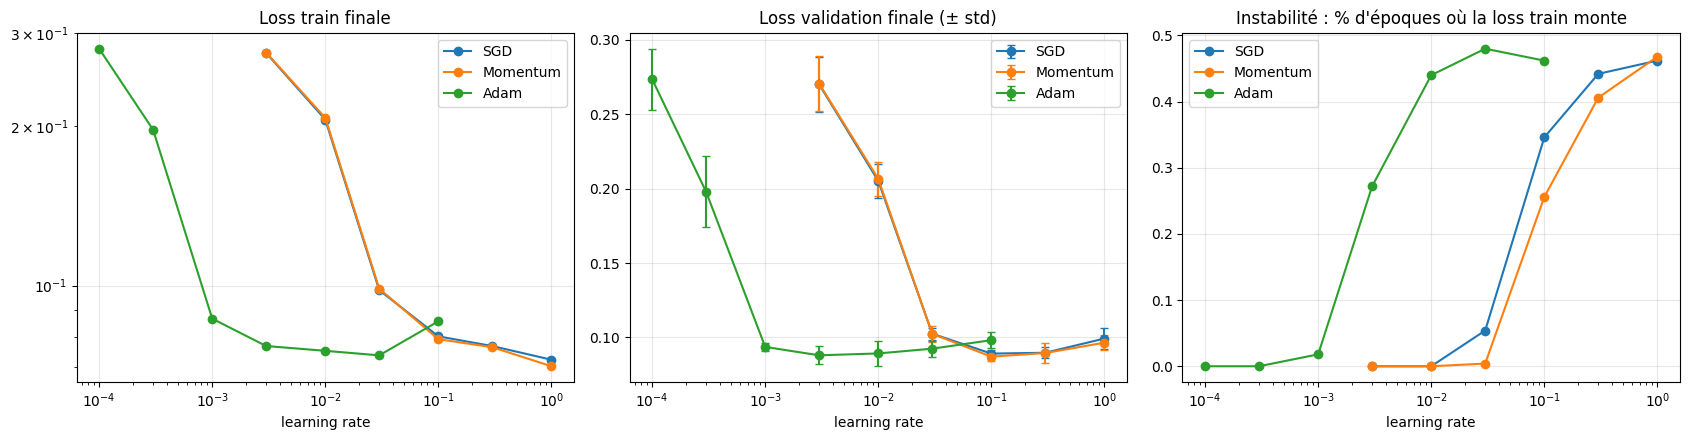

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name in GRIDS:
    g = agg.loc[name]
    ax[0].errorbar(g.index, g.loss_train, color=COLORS[name], marker="o", label=name)
    ax[1].errorbar(g.index, g.loss_val, yerr=g.loss_val_std, color=COLORS[name], marker="o", capsize=3, label=name)
    ax[2].plot(g.index, g.frac_up, color=COLORS[name], marker="o", label=name)
for a, t in zip(ax, ["Loss train finale", "Loss validation finale (± std)", "Instabilité : % d'époques où la loss train monte"]):
    a.set_xscale("log"); a.set_xlabel("learning rate"); a.set_title(t); a.grid(alpha=.3); a.legend()
ax[0].set_yscale("log")
plt.tight_layout(); plt.show()

Deux observations à vérifier sur ces courbes :
- **Trop petit** : le budget de 100 époques est insuffisant (sous-apprentissage), les deux losses restent élevées.
- **Plus grand** : la loss train continue de baisser, mais la loss de validation remonte, et les à-coups d'une époque à l'autre augmentent.

## 4. Choix du learning rate sur la validation
Pour chaque optimiseur, on retient le lr qui minimise la **loss de validation finale moyenne** (le test n'intervient pas).

In [5]:
a = agg.reset_index()
best = a.loc[a.groupby("opt")["loss_val"].idxmin()].set_index("opt")
best_lr = best["lr"].to_dict()
print("lr retenus :", best_lr)
best[["lr", "loss_ep5", "epochs_to_thr", "loss_train", "loss_val", "loss_val_std", "acc_val", "gap", "frac_up"]].round(4)

lr retenus : {'Adam': 0.003, 'Momentum': 0.1, 'SGD': 0.1}


,lr,loss_ep5,epochs_to_thr,loss_train,loss_val,loss_val_std,acc_val,gap,frac_up
opt,,,,,,,,,
Adam,0.003,0.2585,11.0,0.0768,0.0880,0.0062,0.9653,0.0112,0.272
Momentum,0.100,0.2616,12.6,0.0792,0.0871,0.0028,0.9707,0.0080,0.256
SGD,0.100,0.2576,11.8,0.0801,0.0892,0.0022,0.9700,0.0090,0.346


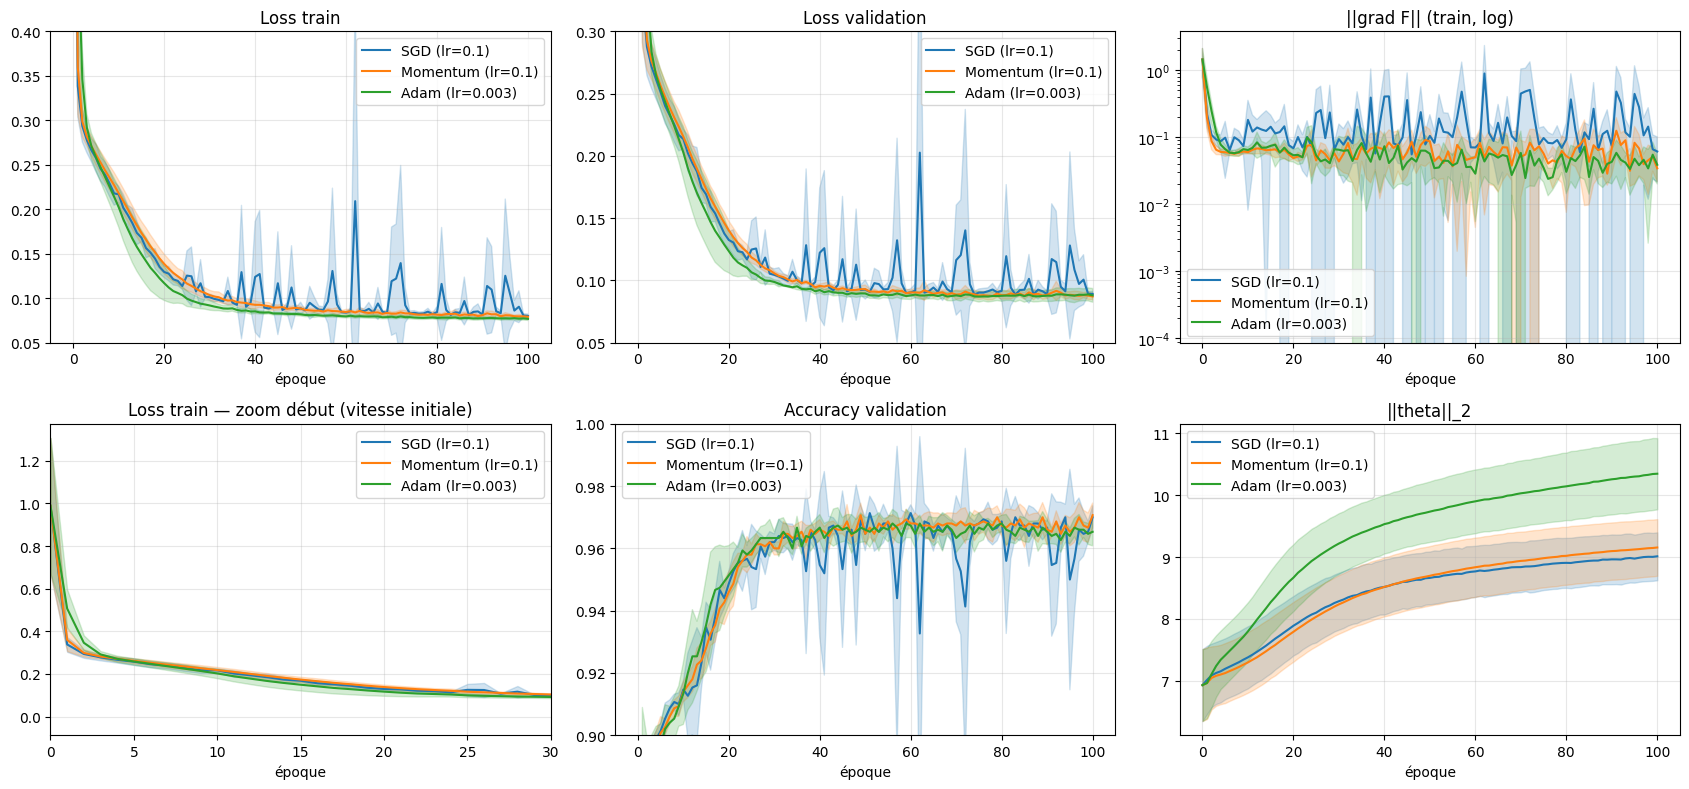

In [6]:
# Courbes moyennes ± std (sur les 5 seeds) au meilleur lr de chaque optimiseur
hist_best = {n: [results[(n, best_lr[n], s)] for s in SEEDS] for n in GRIDS}

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for n, hs in hist_best.items():
    c = COLORS[n]; lab = f"{n} (lr={best_lr[n]:g})"
    plot_mean_std(ax[0, 0], hs, "loss_train", lab, c)
    plot_mean_std(ax[0, 1], hs, "loss_val", lab, c)
    plot_mean_std(ax[0, 2], hs, "grad_norm", lab, c, logy=True)
    plot_mean_std(ax[1, 0], hs, "loss_train", lab, c)           # zoom sur les 30 premières époques
    plot_mean_std(ax[1, 1], hs, "acc_val", lab, c)
    plot_mean_std(ax[1, 2], hs, "weight_norm", lab, c)
titles = ["Loss train", "Loss validation", "||grad F|| (train, log)",
          "Loss train — zoom début (vitesse initiale)", "Accuracy validation", "||theta||_2"]
for k, (axx, t) in enumerate(zip(ax.ravel(), titles)):
    axx.set_title(t); axx.set_xlabel("époque"); axx.grid(alpha=.3); axx.legend()
ax[1, 0].set_xlim(0, 30); ax[1, 1].set_ylim(0.9, 1.0); ax[0, 1].set_ylim(0.05, 0.3); ax[0, 0].set_ylim(0.05, 0.4)
plt.tight_layout(); plt.show()

## 5. Tableau de synthèse aux meilleurs learning rates (moyenne ± écart-type, 5 seeds)

In [7]:
def ms(x, d=4): return f"{np.mean(x):.{d}f} ± {np.std(x, ddof=1):.{d}f}"

summary = []
for n in GRIDS:
    d_ = df[(df.opt == n) & (df.lr == best_lr[n])]
    summary.append({
        "optimiseur": n, "lr": best_lr[n],
        "loss train ép.5": ms(d_.loss_train_ep5),
        f"ép. pour loss<{THR}": ms(d_.epochs_to_thr, 1),
        "loss train finale": ms(d_.loss_train_final),
        "loss val finale": ms(d_.loss_val_final),
        "acc val": ms(d_.acc_val_final, 3),
        "% époques loss↑": ms(d_.frac_up, 2),
    })
pd.DataFrame(summary).set_index("optimiseur")

,lr,loss train ép.5,ép. pour loss<0.2,loss train finale,loss val finale,acc val,% époques loss↑
optimiseur,,,,,,,
SGD,0.100,0.2576 ± 0.0174,11.8 ± 1.9,0.0801 ± 0.0023,0.0892 ± 0.0022,0.970 ± 0.004,0.35 ± 0.05
Momentum,0.100,0.2616 ± 0.0131,12.6 ± 1.8,0.0792 ± 0.0015,0.0871 ± 0.0028,0.971 ± 0.004,0.26 ± 0.04
Adam,0.003,0.2585 ± 0.0171,11.0 ± 3.0,0.0768 ± 0.0020,0.0880 ± 0.0062,0.965 ± 0.005,0.27 ± 0.06


## 6. L'optimiseur le plus rapide sur la loss train généralise-t-il le mieux ?
On compare, pour chaque optimiseur, (a) la configuration **la plus rapide** (moins d'époques pour passer sous le seuil) et (b) la configuration **qui généralise le mieux** (plus faible loss val).

In [8]:
a2 = agg.reset_index()
a2["speed"] = a2.epochs_to_thr.fillna(EPOCHS + 1)
fast = a2.loc[a2.groupby("opt")["speed"].idxmin()].set_index("opt")
comp = pd.concat({"la + rapide": fast, "meilleure val": best.reset_index().set_index("opt")}, axis=1)
comp.loc[:, (slice(None), ["lr", "epochs_to_thr", "loss_train", "loss_val", "gap", "acc_val"])].round(4)

,la + rapide,meilleure val,la + rapide,meilleure val,la + rapide,meilleure val,la + rapide,meilleure val,la + rapide,meilleure val,la + rapide,meilleure val
,lr,lr,epochs_to_thr,epochs_to_thr,loss_train,loss_train,loss_val,loss_val,gap,gap,acc_val,acc_val
opt,,,,,,,,,,,,
Adam,0.1,0.003,1.4,11.0,0.0856,0.0768,0.0982,0.0880,0.0126,0.0112,0.9627,0.9653
Momentum,1.0,0.100,2.2,12.6,0.0704,0.0792,0.0965,0.0871,0.0262,0.0080,0.9633,0.9707
SGD,1.0,0.100,3.0,11.8,0.0724,0.0801,0.0993,0.0892,0.0269,0.0090,0.9653,0.9700


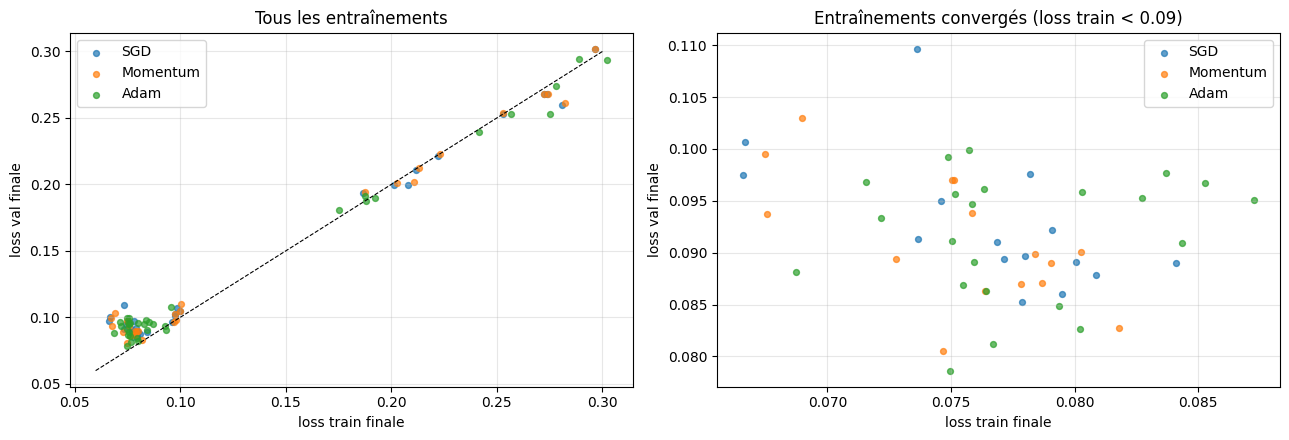

Spearman train/val, tous les runs       : rho = +0.74 (p = 1.7e-17, n = 95)
Spearman train/val, runs convergés      : rho = -0.31 (p = 0.024, n = 52)


In [9]:
# Relation loss train finale <-> loss val finale sur TOUS les entraînements
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n in GRIDS:
    d_ = df[df.opt == n]
    ax[0].scatter(d_.loss_train_final, d_.loss_val_final, s=18, alpha=.7, color=COLORS[n], label=n)
ax[0].plot([0.06, 0.3], [0.06, 0.3], "k--", lw=.8)
ax[0].set_xlabel("loss train finale"); ax[0].set_ylabel("loss val finale"); ax[0].set_title("Tous les entraînements")
ax[0].legend(); ax[0].grid(alpha=.3)

conv = df[df.loss_train_final < 0.09]       # entraînements « bien convergés » (hors sous-apprentissage)
for n in GRIDS:
    d_ = conv[conv.opt == n]
    ax[1].scatter(d_.loss_train_final, d_.loss_val_final, s=18, alpha=.7, color=COLORS[n], label=n)
ax[1].set_xlabel("loss train finale"); ax[1].set_ylabel("loss val finale")
ax[1].set_title("Entraînements convergés (loss train < 0.09)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

rho_all, p_all = spearmanr(df.loss_train_final, df.loss_val_final)
rho_c, p_c = spearmanr(conv.loss_train_final, conv.loss_val_final)
print(f"Spearman train/val, tous les runs       : rho = {rho_all:+.2f} (p = {p_all:.1e}, n = {len(df)})")
print(f"Spearman train/val, runs convergés      : rho = {rho_c:+.2f} (p = {p_c:.3f}, n = {len(conv)})")

### Réponse (pour ce problème et ce protocole)

**Vitesse initiale.** Adam est le plus rapide à un lr donné : à son meilleur lr, il atteint le seuil en environ 11 époques, contre environ 12 pour SGD et Momentum à leurs meilleurs lr ; avec un lr plus grand (0.03 à 0.1), il y arrive en 1 à 2 époques. Aux meilleurs lr, les trois optimiseurs sont proches.

**Momentum et SGD.** Avec la forme $v_{k+1}=\beta v_k+(1-\beta)g_k$ , la vitesse est une *moyenne glissante* des gradients, et non une accumulation : la taille de pas effective reste celle de SGD au même lr. C'est pourquoi les courbes de Momentum et de SGD sont presque superposées. Le gain de Momentum est lissé, pas accéléré.

**Stabilité.** La part d'époques où la loss d'entraînement augmente grimpe avec le lr, pour les trois méthodes (de ≈ 0 à ≈ 0.45). Aucun entraînement ne diverge, mais les gros lr oscillent davantage.

**Sensibilité au lr.** Les trois optimiseurs sont très sensibles : un lr trop petit sous-apprend en 100 époques (loss val ≈ 0.20 à 0.27). Adam a besoin d'un lr plus petit (≈ $10^{-3}$ à $10^{-2}$) que SGD (≈ 0.1 à 0.3), mais couvre une plage utile de même largeur.

**Validation.** Aux meilleurs lr, les trois optimiseurs sont **statistiquement indiscernables** : loss val ≈ 0.087 à 0.089 avec un écart-type de 0.003 à 0.006 entre seeds, soit plus que l'écart entre optimiseurs. On ne peut pas déclarer de gagnant.

**Question centrale.** Non, aller plus vite ou descendre plus bas sur le train ne garantit pas de mieux généraliser :
- *À l'intérieur d'un même optimiseur*, augmenter le lr accélère la baisse de la loss train et l'abaisse davantage, mais la loss de validation remonte et l'écart val − train s'élargit (par exemple Adam : de 0.007 à lr = 1e-3 jusqu'à ≈ 0.019 à lr = 0.03). La configuration la plus rapide n'est pas celle qui généralise le mieux.
- *Entre runs bien convergés*, la corrélation entre loss train et loss val est faible ou négative, et fragile au choix du seuil : il n'y a pas de preuve qu'une loss train plus basse donne une meilleure validation. La corrélation positive sur l'ensemble des runs vient surtout du sous-apprentissage, où les deux losses sont hautes.
- *Entre optimiseurs*, après réglage du lr, les différences de validation sont dans le bruit.

**Limites.** 5 seeds seulement ; un seul split des données ; grille de lr grossière (facteur ≈ 3) ; budget fixé à 100 époques (ce qui pénalise les petits lr) ; le choix du lr et l'évaluation utilisent le même jeu de validation (légèrement optimiste) ; jeu de test volontairement non consulté ; problème simple (2D, 1500 points) où l'erreur irréductible due au bruit limite les écarts possibles.

In [11]:
# Sauvegarde pour le notebook de synthèse (10) et le rapport
os.makedirs("../results", exist_ok=True)
df.to_csv("../results/c2_runs.csv", index=False)
agg.round(6).to_csv("../results/c2_aggregated.csv")
with open("../results/c2_histories_best.pkl", "wb") as f:
    pickle.dump({"best_lr": best_lr, "histories": hist_best}, f)
print("Résultats sauvegardés dans ../results/")

Résultats sauvegardés dans ../results/


## 7. Livrable J2 : figures et tableau comparatif pour le rapport


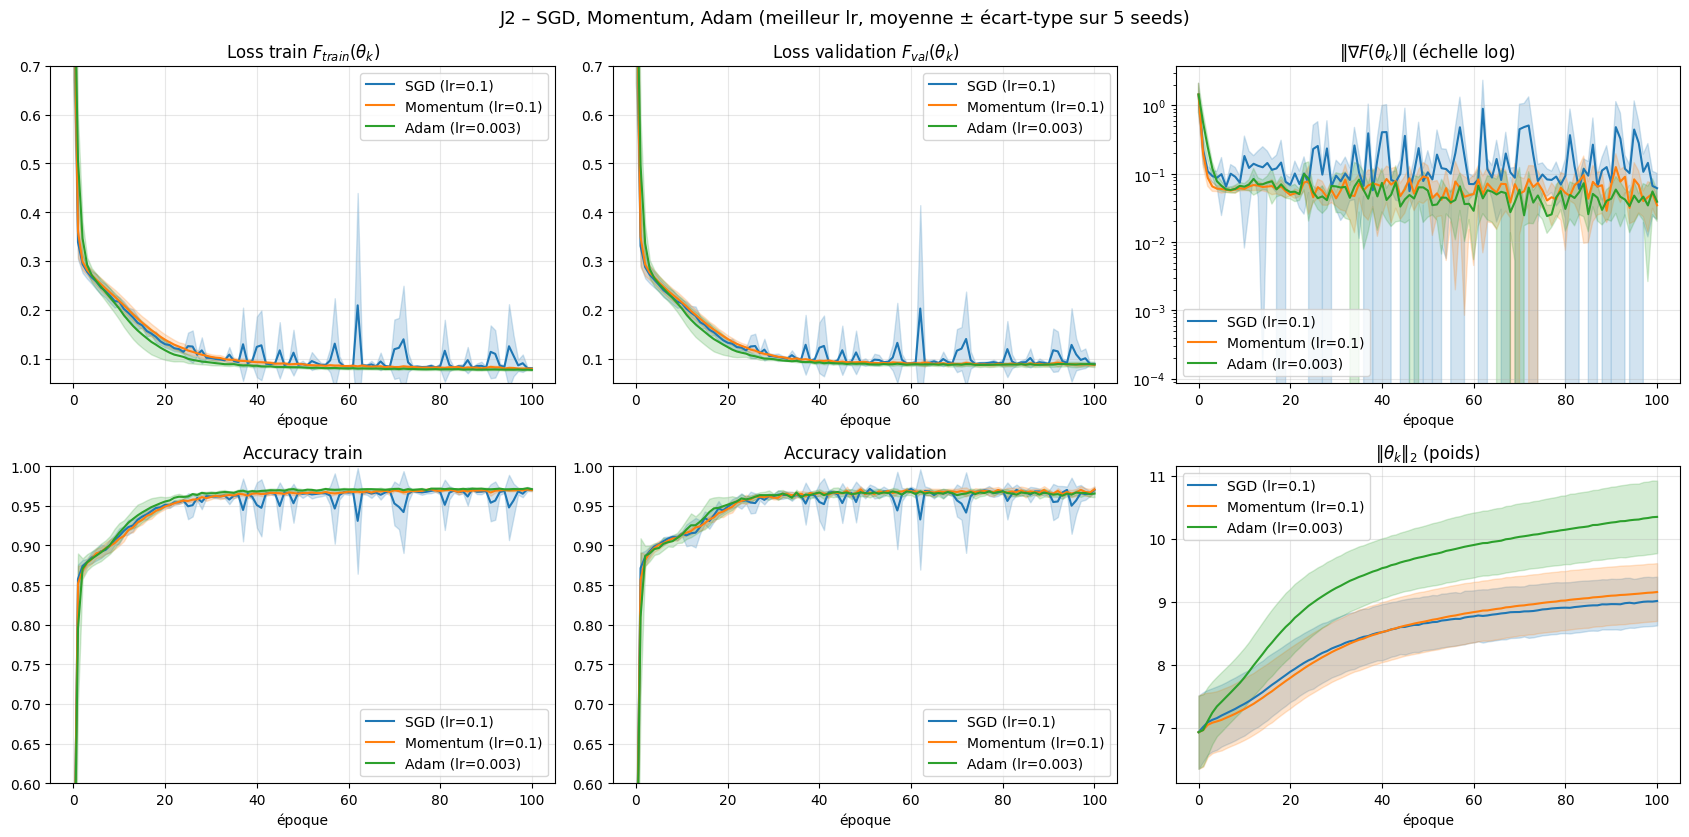

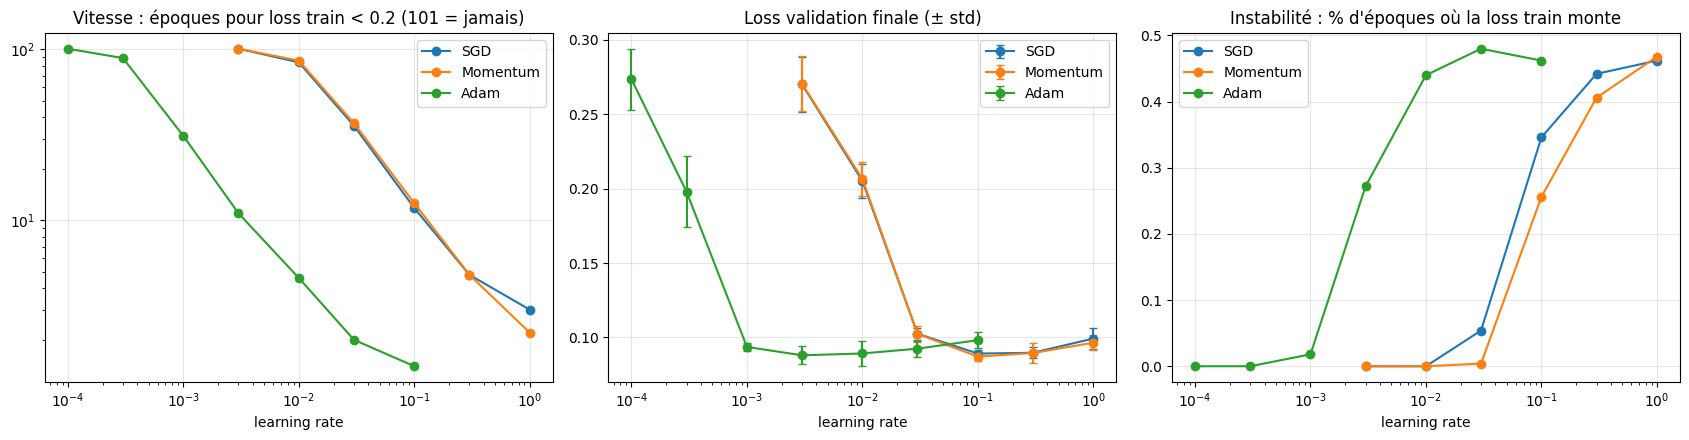

| optimiseur | lr | loss train ép.5 | ép. pour loss<0.2 | loss train finale | loss val finale | acc val | % époques loss↑ |
|---|---|---|---|---|---|---|---|
| SGD | 0.1 | 0.2576 ± 0.0174 | 11.8 ± 1.9 | 0.0801 ± 0.0023 | 0.0892 ± 0.0022 | 0.970 ± 0.004 | 0.35 ± 0.05 |
| Momentum | 0.1 | 0.2616 ± 0.0131 | 12.6 ± 1.8 | 0.0792 ± 0.0015 | 0.0871 ± 0.0028 | 0.971 ± 0.004 | 0.26 ± 0.04 |
| Adam | 0.003 | 0.2585 ± 0.0171 | 11.0 ± 3.0 | 0.0768 ± 0.0020 | 0.0880 ± 0.0062 | 0.965 ± 0.005 | 0.27 ± 0.06 |


In [12]:
os.makedirs("../results/figures", exist_ok=True)

# --- Figure 1 : courbes des trois optimiseurs (époque 0 = avant entraînement) ---
fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
panels = [("loss_train", "Loss train $F_{train}(\\theta_k)$", False),
          ("loss_val", "Loss validation $F_{val}(\\theta_k)$", False),
          ("grad_norm", "$\\|\\nabla F(\\theta_k)\\|$ (échelle log)", True),
          ("acc_train", "Accuracy train", False),
          ("acc_val", "Accuracy validation", False),
          ("weight_norm", "$\\|\\theta_k\\|_2$ (poids)", False)]
for axx, (key, title, logy) in zip(ax.ravel(), panels):
    for n, hs in hist_best.items():
        plot_mean_std(axx, hs, key, f"{n} (lr={best_lr[n]:g})", COLORS[n], logy=logy)
    axx.set_title(title); axx.set_xlabel("époque"); axx.grid(alpha=.3); axx.legend()
ax[0, 0].set_ylim(0.05, 0.7); ax[0, 1].set_ylim(0.05, 0.7)
ax[1, 0].set_ylim(0.6, 1.0); ax[1, 1].set_ylim(0.6, 1.0)
fig.suptitle("J2 – SGD, Momentum, Adam (meilleur lr, moyenne ± écart-type sur 5 seeds)", fontsize=13)
plt.tight_layout(); fig.savefig("../results/figures/j2_curves.png", dpi=150); plt.show()

# --- Figure 2 : sensibilité au learning rate ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name in GRIDS:
    g = agg.loc[name]
    ax[0].plot(g.index, g.epochs_to_thr.fillna(EPOCHS + 1), color=COLORS[name], marker="o", label=name)
    ax[1].errorbar(g.index, g.loss_val, yerr=g.loss_val_std, color=COLORS[name], marker="o", capsize=3, label=name)
    ax[2].plot(g.index, g.frac_up, color=COLORS[name], marker="o", label=name)
titles = [f"Vitesse : époques pour loss train < {THR} ({EPOCHS+1} = jamais)",
          "Loss validation finale (± std)",
          "Instabilité : % d'époques où la loss train monte"]
for a_, t in zip(ax, titles):
    a_.set_xscale("log"); a_.set_xlabel("learning rate"); a_.set_title(t); a_.grid(alpha=.3); a_.legend()
ax[0].set_yscale("log")
plt.tight_layout(); fig.savefig("../results/figures/j2_lr_sensitivity.png", dpi=150); plt.show()

# --- Tableau comparatif (CSV + Markdown) ---
table = pd.DataFrame(summary).set_index("optimiseur")
table.to_csv("../results/j2_table.csv")
cols = ["optimiseur"] + list(table.columns)
md_lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
for name, row in table.iterrows():
    md_lines.append("| " + " | ".join([name] + [str(v) for v in row.values]) + " |")
open("../results/j2_table.md", "w").write("\n".join(md_lines) + "\n")
print("\n".join(md_lines))